# Lecture 22

Lets walk through building a very simple Deep Neural Network for our Tabular datasets.

First, lets take a quick walk-through of [Keras](https://keras.io).


## Tabular Data

I've copied all of my functions that loaded and visualized the data from from my previous notbook into a module, so that I can use them here:

In [1]:
!ls Train/337_361065  # Fixed 2026-10: "Train/" (was "train/", which works only on a Mac); the dataset used below

attribute_names.json	    data_test.parquet	target_train.parquet
categorical_indicator.json  data_train.parquet


In [2]:
from dataloader import *

Processing: 334_361110
Processing: 334_361111
Processing: 334_361113
Processing: 334_361282
Processing: 334_361283
Processing: 334_361285
Processing: 334_361286
Processing: 335_361093
Processing: 335_361094
Processing: 335_361096
Processing: 335_361097
Processing: 335_361098
Processing: 335_361099
Processing: 335_361101
Processing: 335_361102
Processing: 335_361103
Processing: 335_361104
Processing: 335_361287
Processing: 335_361288
Processing: 335_361289
Processing: 335_361291
Processing: 335_361292
Processing: 335_361293
Processing: 335_361294
Processing: 336_361072
Processing: 336_361073
Processing: 336_361074
Processing: 336_361076
Processing: 336_361077
Processing: 336_361078
Processing: 336_361079
Processing: 336_361080
Processing: 336_361081
Processing: 336_361082
Processing: 336_361083
Processing: 336_361084
Processing: 336_361085
Processing: 336_361086
Processing: 336_361087
Processing: 336_361088
Processing: 336_361279
Processing: 336_361280
Processing: 336_361281
Processing:

**Why a module.** The functions from the tabular-data lecture (`load_dataset`, `compare_features_binary`
and the loop that sorts the datasets into binary, multiclass and regression) now live in
`dataloader.py`, a **module**: a `.py` file of code you `import`. A first exploration is messy scratch
work. Once you know what you want, "you write it in a nice piece of code", and you "checkpoint
yourself": the module is fixed, there is one definitive version, and every notebook that imports it gets
the same thing. The first requirement for any result is that it is **reproducible**: that a clean,
top-to-bottom run gives it again. Cells run in a funny order are not.

It is not perfect: importing the module reads every one of the 59 datasets to build the summary
table, which this notebook doesn't need. That is why the import is slow, and why it prints a line per
dataset. A better module would do that work inside a function, only when asked.

**Corrected 2026-10:** the module and the next cell used to look for `"train/"` in lower case, which
only works on a Mac, where file names ignore case; the folder is `"Train/"`. The file lists are now
sorted, so they come out in the same order on every computer.

In [3]:
import glob 
import pandas as pd
PATH = "./"
# Fixed 2026-10: "Train/" (was "train/"), and sorted, so the order is the same on every computer
target_files = sorted(glob.glob(PATH+"Train/*/target_train.parquet"))

print(target_files)

df = pd.read_parquet(target_files[7])

['./Train/334_361110/target_train.parquet', './Train/334_361111/target_train.parquet', './Train/334_361113/target_train.parquet', './Train/334_361282/target_train.parquet', './Train/334_361283/target_train.parquet', './Train/334_361285/target_train.parquet', './Train/334_361286/target_train.parquet', './Train/335_361093/target_train.parquet', './Train/335_361094/target_train.parquet', './Train/335_361096/target_train.parquet', './Train/335_361097/target_train.parquet', './Train/335_361098/target_train.parquet', './Train/335_361099/target_train.parquet', './Train/335_361101/target_train.parquet', './Train/335_361102/target_train.parquet', './Train/335_361103/target_train.parquet', './Train/335_361104/target_train.parquet', './Train/335_361287/target_train.parquet', './Train/335_361288/target_train.parquet', './Train/335_361289/target_train.parquet', './Train/335_361291/target_train.parquet', './Train/335_361292/target_train.parquet', './Train/335_361293/target_train.parquet', './Train/3

In [4]:
# Fixed 2026-10: by name (was binary_classification_datasets[7], which depends on the file order)
d1=load_dataset("337_361065")   # the MAGIC gamma telescope data

## The data: the MAGIC gamma telescope

This dataset was chosen, by looking through the binary datasets, because "it's got features that show
some separation". (It used to be picked as `binary_classification_datasets[7]`, but that position
depends on the order the computer lists the files in, so on another computer it was a different
dataset. It is now picked by name.)

It is the **MAGIC gamma telescope** dataset (UCI; Bock et al. 2004), and it is physics. When a
high-energy gamma ray, or a cosmic-ray proton or nucleus (a **hadron**), hits the upper atmosphere, it
makes an **air shower**: a cascade of charged particles moving faster than light does in air, which
therefore emit a faint flash of blue **Cherenkov light**. A ground-based **imaging Cherenkov telescope**
photographs the flash. In the camera a shower looks like an ellipse, and the features are the ellipse's
shape, the **Hillas parameters**:

- `fLength`, `fWidth`: the major and minor axes of the ellipse (mm); `fSize`: log of the total light;
- `fConc`, `fConc1`: the fraction of the light in the two brightest pixels, and in the brightest one;
- `fAsym`, `fM3Long`, `fM3Trans`: how lopsided the ellipse is;
- `fAlpha`: the angle between the ellipse's long axis and the line to the centre of the camera (degrees);
- `fDist`: the distance of the ellipse's centre from the centre of the camera.

The data are simulated showers. **Class 0 is gamma** (the signal a gamma-ray astronomer is after) and
**class 1 is hadron** (the background): class 0's average `fAlpha` is 19°, class 1's is 44°. The benchmark
balanced the two classes, which is why there are about as many of each.

Number of catogory 0: 4026
Number of catogory 1: 3999
Found 10 features. Creating grid of 4 by 3
fLength: KS Distribution Similarity Test: 0.23486721158680132
fWidth: KS Distribution Similarity Test: 0.21895041569632348
fSize: KS Distribution Similarity Test: 0.12879207134123322
fConc: KS Distribution Similarity Test: 0.07822205178716438
fConc1: KS Distribution Similarity Test: 0.07516092883131364
fAsym: KS Distribution Similarity Test: 0.16385560622644485
fM3Long: KS Distribution Similarity Test: 0.1969147279368277
fM3Trans: KS Distribution Similarity Test: 0.1055329033450613
fAlpha: KS Distribution Similarity Test: 0.45540930687217257
fDist: KS Distribution Similarity Test: 0.07662981319100266


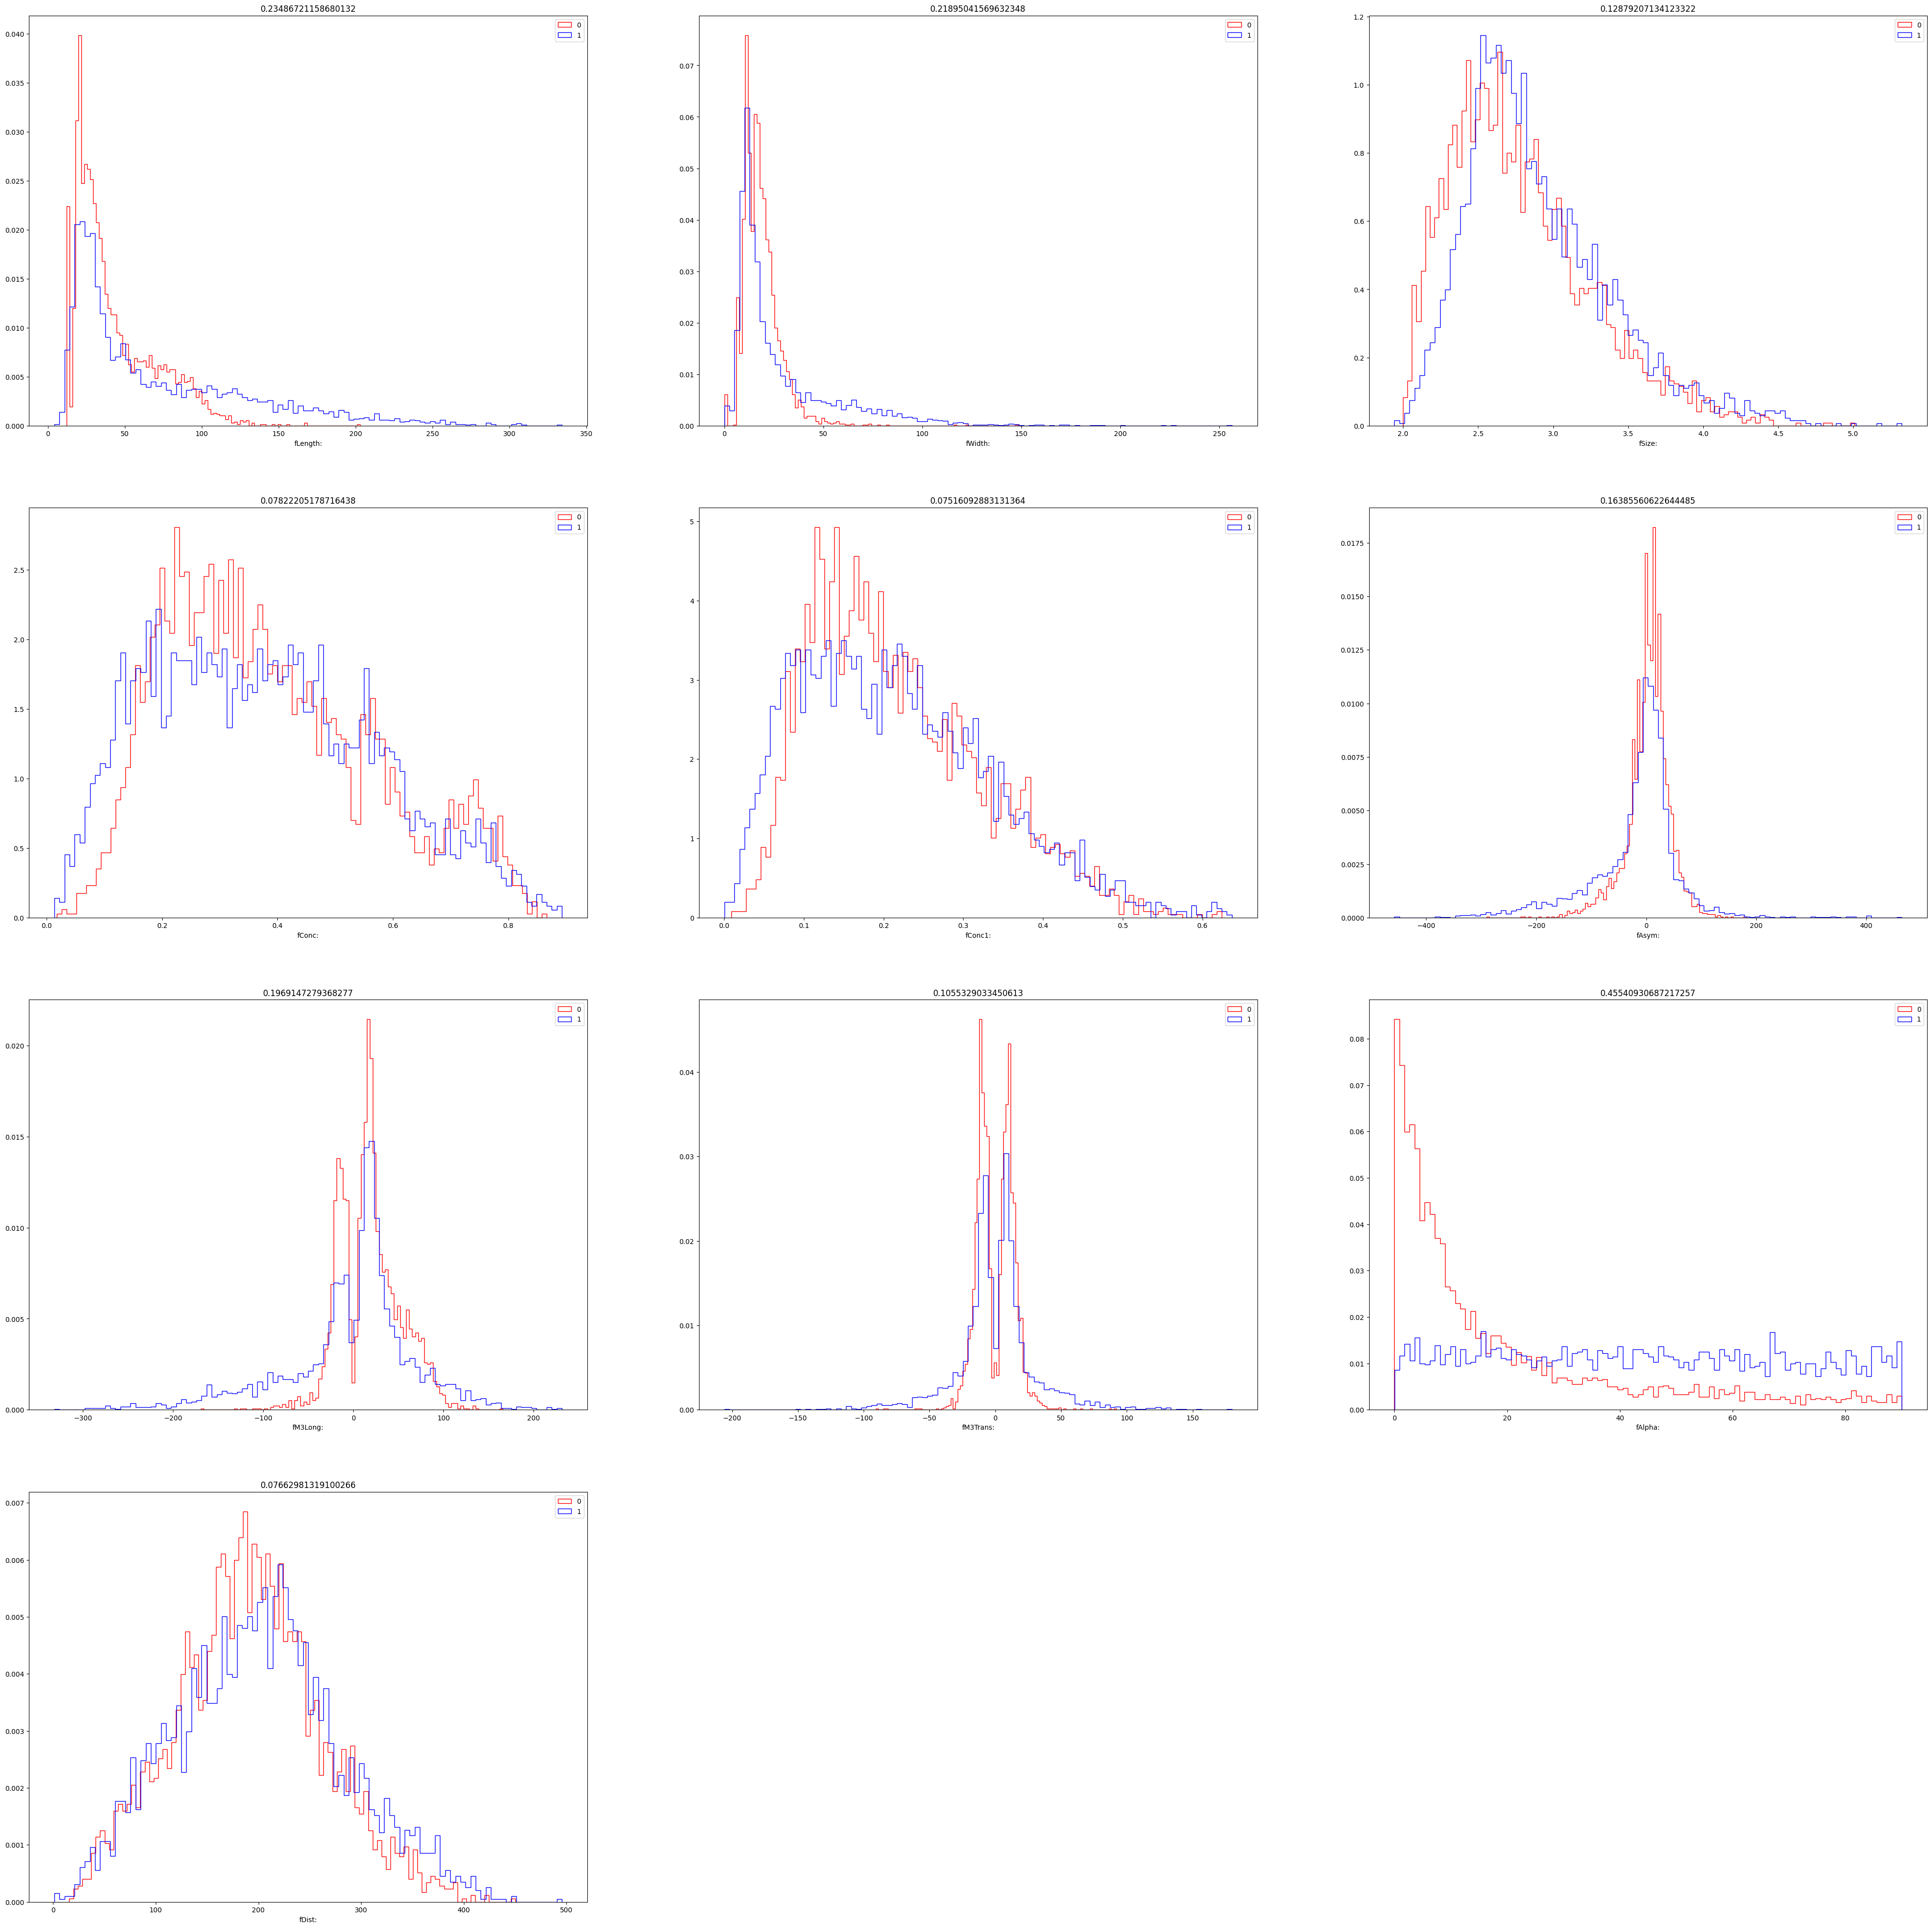

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt
compare_features_binary(d1)

`fAlpha` separates the classes best (KS 0.455), and the physics says why. The telescope points at a
gamma-ray source, and a gamma shower points back at where it came from, so its image's long axis points
at the centre of the camera: small `fAlpha`. Hadron showers come from every direction.

**A one-feature baseline.** "If I was actually going to get a baseline from this, the easiest thing
would be, this feature is great." Using `fAlpha` alone as the classifier's output gives an AUC of 0.78
on the test slice below: "at least I should do this well". (Baselines were discussed in the Keras
lecture.)

Quickly, we'll split our data into Training and Test subsets:

In [6]:
import math

N_total = d1["Training"].shape[0]
N_train = math.floor(.8*N_total)
N_val = math.floor((N_total-N_train)/2.)
N_test = math.floor((N_total-N_train)/2.)

X_Train = d1["Training"][:N_train]
y_Train = d1["Target"][:N_train]

X_val = d1["Training"][N_train:N_val+N_train]
y_val = d1["Target"][N_train:N_val+N_train]
                     
X_Test = d1["Training"][N_train+N_val:N_test+N_val+N_train]
y_Test = d1["Target"][N_train+N_val:N_test+N_val+N_train]

N_val

802

In [7]:
N_train

6420

Three slices, 80/10/10: training, validation and test (the roles of validation and test are explained in
the Keras lecture). The benchmark's rows are already shuffled, so slicing in order is safe here.

## Building our first model

Here's our first model:

In [9]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential()
model.add(Dense(12, input_dim=X_Train.shape[1], activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Here we are specifying a few of the hyperparameters:

* The network architecture: we have 3 hidden layers, with 12, 8, and 8 neurons in each, respectively.
* We selected ReLU for the activations in the hidden layers.
* Because we are doing binary classifications, we selected sigmoid as the output activation.

Recall that the output activation corresponds to your task:
* Binary Classification: sigmoid
* Multi-class classification: softmax
* Regression: linear

Now let's quickly make sure we understand the number of parameters in our model. The number of input features:

In [10]:
X_Train.shape[1]

10

Lets quickly compute the number of parameters we expect in our model, layer by layer:

In [11]:
# 1st Hidde layer
X_Train.shape[1]*12 + 12

132

In [12]:
# 2nd Hidden layer
12 * 8 + 8

104

In [13]:
# 3rd Hidden layer
8 * 8 + 8

72

And the output layer: 8 × 1 + 1 = 9. In total 132 + 104 + 72 + 9 = **317** parameters. Only the first
layer changed from the SUSY model, because there are 10 inputs instead of 18.

You can have Keras print out the model for you to investigate:

In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 317 (1.24 KB)

 Trainable params: 317 (1.24 KB)

 Non-trainable params: 0 (0.00 B)

The preferred method of creating a model is to use functional API, where the Deep Neural Network is viewed as a composition of functions. With this API, you can create very sophisticated models with multiple inputs and outputs.

In [15]:
from keras.models import Model
from keras.layers import Dense, Input

in_x = Input(shape = X_Train.shape[1:])
x = Dense(12, input_dim=X_Train.shape[1], activation='relu')(in_x)
x = Dense(8, activation='relu')(x)
x = Dense(8, activation='relu')(x)
out_x = Dense(1, activation='sigmoid')(x)

model = Model(in_x,out_x)

model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 12)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 317 (1.24 KB)

 Trainable params: 317 (1.24 KB)

 Non-trainable params: 0 (0.00 B)

Few things to notice:
* Activations can be specified here, but can be added as their own layers.
* Note that in most cases where you are using existing Keras components with their default configuration, you can just specify the object you want by name. If you want to change a default, you'll have to create an instance of the object.

Since we haven't done any data normalization, we'll also add a layer to the model that does the normalization:

In [16]:
from keras.activations import relu
import keras

in_x = Input(shape = X_Train.shape[1:])
# Fixed 2026-10: the normalization is learned from the training sample (adapt) and the first Dense
# layer is applied to its output (it was applied to in_x, so the normalization was not in the model)
normalizer = keras.layers.Normalization(axis=-1)
normalizer.adapt(X_Train.to_numpy().astype("float"))
x = normalizer(in_x)
x = Dense(12, input_dim=X_Train.shape[1], activation='relu')(x)
x = Dense(8)(x)
x = relu(x)
# Fixed 2026-10: the second Dense(8) restored (without it this model had 245 parameters, not 317)
x = Dense(8)(x)
x = relu(x)
out_x = Dense(1, activation='sigmoid')(x)

model = Model(in_x,out_x)

model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 10)             │            21 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 12)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338 (1.32 KB)

 Trainable params: 317 (1.24 KB)

 Non-trainable params: 21 (88.00 B)

## The Normalization layer

The features have very different ranges: `fDist` goes up to about 500, `fAsym` from about −460 to
+460, `fConc` from 0 to 0.9. Training works much better when every input has about the same range, so we
**standardize** each feature: subtract its mean and divide by its standard deviation, as
`StandardScaler` did in scikit-learn.

A `Normalization` layer does this *inside the model*. `adapt` plays the role of the scaler's `fit`: it
computes each feature's mean and variance from the data you give it, which must be the **training**
sample. Calling the layer is the `transform`. Being part of the model, the scaling travels with it:
whoever uses the model doesn't need your preprocessing code.

Read the summary: the `normalization` row has **21 non-trainable parameters**, a mean and a variance for
each of the 10 features plus a count. They are stored with the model but training never changes them.
The other 317 are the same as before.

**Corrected 2026-10.** This cell used to create the `Normalization` layer and then connect the first
`Dense` layer to `in_x` instead of to its output, so the normalization was not part of the model (its
summary had no normalization row), and the layer was never adapted. The same cell had also lost one
`Dense(8)` (245 parameters), as in the Keras lecture. Both are fixed, and everything trained below is
this model.

Once the DNN has been specified, we will have to further forumlate our problem by specifing the loss (the parameter which will be optimized during training), and the optimizer (the optimization algorithm). In Keras, these are specified at "compile" time:

In [17]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

Quick guide for selecting loss function:

* Binary Classification: binary_crossentropy
* Multi-class classification: categorical_crossentropy
* Regression: MSE

Note that we also specified a metric which Keras will compute for us during training so we can keep track of the progress of training. 

The output activation and the loss go together:

- **binary classification**: one output with a **sigmoid**, and **binary cross-entropy**;
- **multi-class classification**: one output per class with a **softmax**, which makes the outputs
  positive and sum to one, so they read as probabilities, and **categorical cross-entropy**. That loss
  expects the target **one-hot encoded** (`[0, 1, 0]` for the second of three classes); with the
  target as an integer label (0, 1, 2), use `sparse_categorical_crossentropy`;
- **regression**: one output with no activation (linear), and the **mean squared error** (`'mse'`).

Mean squared error is a poor loss for classification: its gradients become tiny when the output is
confidently wrong, so learning stalls exactly where it should be fastest.

Few things to define and be aware of before we train:

* An epoch is defined as one training pass using the whole training data.
* Epochs are broken into smaller steps. At each step a subset of the training data, referred to as a batch, is used to compute the gradients perform an optimization step. Taking many steps is an example of stochastic gradient decent, which is an important ingredient to getting Deep Learning working.
* In order to monitor the training process, we typically compare the performance on the training sample and another sample (validation sample in Keras).

The easiest way to train is to use the `fit` method:

In [18]:
history=model.fit(X_Train.to_numpy().astype("float"), 
                  y_Train.to_numpy().astype("float"), 
                  validation_data=(X_val.to_numpy(),y_val.to_numpy()),  # Fixed 2026-10: validate on X_val (was X_Test) 
                  epochs=100, batch_size=10)

Epoch 1/100
642/642 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7383 - loss: 0.5306 - val_accuracy: 0.7743 - val_loss: 0.4517
Epoch 2/100
642/642 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7752 - loss: 0.4567 - val_accuracy: 0.7830 - val_loss: 0.4296
Epoch 3/100
642/642 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7815 - loss: 0.4438 - val_accuracy: 0.8005 - val_loss: 0.4174
Epoch 4/100
642/642 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7908 - loss: 0.4343 - val_accuracy: 0.7993 - val_loss: 0.4121
Epoch 5/100
642/642 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7984 - loss: 0.4235 - val_accuracy: 0.8005 - val_loss: 0.4065
Epoch 6/100
642/642 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8079 - loss: 0.4128 - val_accuracy: 0.8080 - val_loss: 0.3985
Epoch 7/100
642/642 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8159 - loss: 0.4015 - val_accuracy: 0.8192 - val_loss: 0.3953
Epoch 8/100
642/642 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8209 - loss: 0.3910 - val_accu

Reading this run (the progress lines are explained in the Keras lecture):

- The first epoch's training loss is 0.53. Before the normalization was in the model it was **3.16**:
  with raw inputs in the hundreds, the first steps produced wildly wrong outputs.
- **642 steps** per epoch: 6,420 training examples in batches of 10. Such small batches make each epoch
  slow; a power of two such as 64 or 128 would be faster.
- **Corrected 2026-10:** `validation_data` now uses the validation sample, `X_val`; it used to be the test
  sample, although the validation slice had been made for exactly this.

Note that `fit` takes care of

* Running multiple epochs
* Dividing the data into batches
* Computing gradient on each batch
* Using optimizer to take step
* Evaluating performance on training and testing data
* Keep track of everything

But in some instances you may wish to consume data from a difference source (rather than a tensor in memory) or do something different (e.g. training an Adversarial network), which will require you to perform some of these steps yourself. Keras provides easy methods to enable such functionality.

The model history keeps track of the loss and accuracy for each epoch. Note that the training above was setup to run on the validation sample at the end of each epoch:

In [19]:
print (history.history)

{'accuracy': [0.7383177280426025, 0.7752336263656616, 0.781464159488678, 0.7908099889755249, 0.7984423637390137, 0.8079439401626587, 0.8158878684043884, 0.8208722472190857, 0.8300623297691345, 0.8338006138801575, 0.836915910243988, 0.8401868939399719, 0.8412772417068481, 0.8448598384857178, 0.845638632774353, 0.8467289805412292, 0.845638632774353, 0.8490654230117798, 0.8503115177154541, 0.8475077748298645, 0.8518691658973694, 0.8512461185455322, 0.850155770778656, 0.8493769764900208, 0.8526479601860046, 0.8471962809562683, 0.8523364663124084, 0.8514018654823303, 0.8534268140792847, 0.8514018654823303, 0.8515576124191284, 0.8529595136642456, 0.8514018654823303, 0.8528037667274475, 0.8517134189605713, 0.8526479601860046, 0.853894054889679, 0.8542056083679199, 0.855140209197998, 0.8515576124191284, 0.8587227463722229, 0.8512461185455322, 0.8524922132492065, 0.8528037667274475, 0.8535825610160828, 0.855140209197998, 0.8537383079528809, 0.8557632565498352, 0.8554517030715942, 0.852803766727

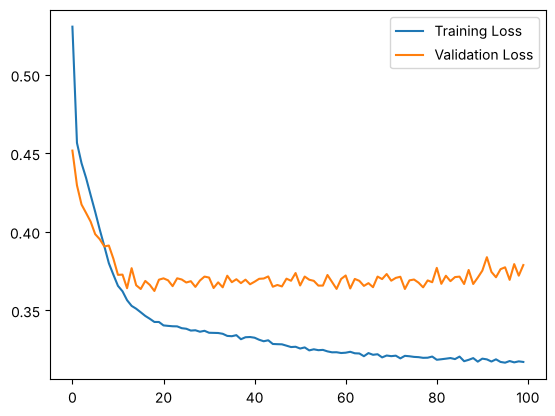

In [20]:
plt.plot(range(len(history.history["loss"])),history.history["loss"],label="Training Loss")
plt.plot(range(len(history.history["val_loss"])),history.history["val_loss"],label="Validation Loss")
plt.legend()

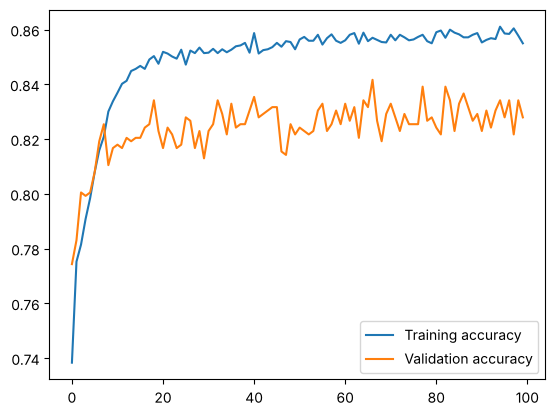

In [21]:
plt.plot(range(len(history.history["accuracy"])),history.history["accuracy"],label="Training accuracy")
plt.plot(range(len(history.history["val_accuracy"])),history.history["val_accuracy"],label="Validation accuracy")
plt.legend()

**Read the curves.** Here the model **over-trains**. The validation loss is lowest at epoch 19 (0.362)
and then drifts up a little (0.379 at epoch 100), while the training loss keeps falling (0.317): the
gap between the curves is the model memorizing its training sample. The validation curve also wiggles
more, because "your statistics for your validation sets are less": it is computed on 802 events,
against 6,420.

Before the fixes, this plot showed the two curves tracking each other for all 100 epochs, and the
lesson in class was that this model was not over-training. The fixed model, with its inputs normalized,
learns much faster and reaches the point where it starts to memorize within twenty epochs. "You have to
look at this": stopping near epoch 19, or keeping the best model with the `EarlyStopping` and
`ModelCheckpoint` callbacks of the Keras lecture, would be the right call.

We can evaluate how the trained model does on the test sample as follows:

In [22]:
scores = model.evaluate(X_Test, y_Test)
print(scores)

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8304 - loss: 0.3906 
[0.3905806243419647, 0.8304239511489868]


Now that validation and test are different samples, this test result (accuracy 0.830) is a genuinely new
number: it is not the last line of the training log (validation accuracy 0.828). No choice was made on
the test sample, so it is an unbiased estimate of how the model does on new data.

While evaluate is useful for assessing performance, once you have trained a model and determined you with to use it, you will want to apply to data without ground truth or the known desired output (in this case signal or background). `predict` enables this functionality:

In [23]:
model.predict(X_Test)

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


array([[0.98299307],
       [0.33697218],
       [0.01861786],
       [0.99142754],
       [0.4343405 ],
       [0.09150648],
       [0.22256725],
       [0.9989939 ],
       [0.14371675],
       [0.81164414],
       [0.3544647 ],
       [0.18627681],
       [0.8529338 ],
       [0.6124582 ],
       [0.4828666 ],
       [0.28940743],
       [0.9999956 ],
       [0.9953229 ],
       [0.9982489 ],
       [0.21523269],
       [0.06515383],
       [0.3596624 ],
       [0.14889455],
       [0.96273774],
       [0.24272954],
       [0.7676071 ],
       [0.00761922],
       [0.09363353],
       [0.555577  ],
       [0.9491926 ],
       [0.51060295],
       [0.11648507],
       [0.11041065],
       [0.19329631],
       [0.9983442 ],
       [0.73394936],
       [0.12421574],
       [0.3906507 ],
       [0.9910608 ],
       [0.9997776 ],
       [0.6753788 ],
       [0.9758121 ],
       [0.08275871],
       [0.9973722 ],
       [0.55567056],
       [0.3382539 ],
       [0.7025153 ],
       [0.146

Note the output here is a number between 0 and 1. Determining what threshold to use to select signal is analgous to what we did for other ML methods.

Lets first look at the distribution of the output of the DNN to confirm visually that things are as we expect:

In [24]:
X_Test_0 = X_Test[(y_Test==0).to_numpy()]
X_Test_1 = X_Test[(y_Test==1).to_numpy()]

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


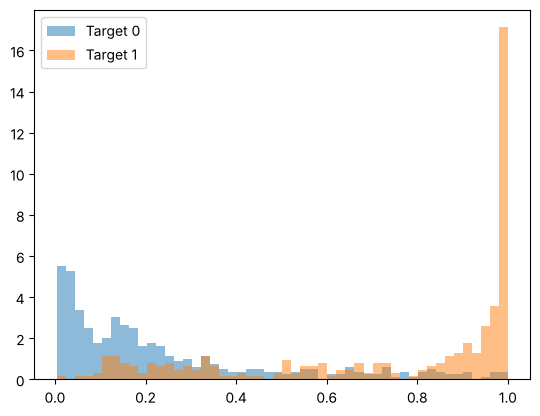

In [25]:
hist,bins,_= plt.hist(model.predict(X_Test_0),density=1,bins=50,alpha=0.5,label="Target 0")
hist,bins,_= plt.hist(model.predict(X_Test_1),density=1,bins=bins,alpha=0.5,label="Target 1")
plt.legend()

**The output is a test statistic.** The network has replaced all 10 features with one number, "a function,
you put all the features in, it gives you back a number". Look at its distribution for the two classes
every time: "you can immediately tell if it's working or not", which a single accuracy number can hide.
Here the gammas (target 0) pile up near 0 and the hadrons (target 1) near 1, with some of both in the
middle. The ROC curve below is read off this plot: move a threshold from 1 down to 0 and count what
fraction of each class lies above it.

Next, we make ROC curves:

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


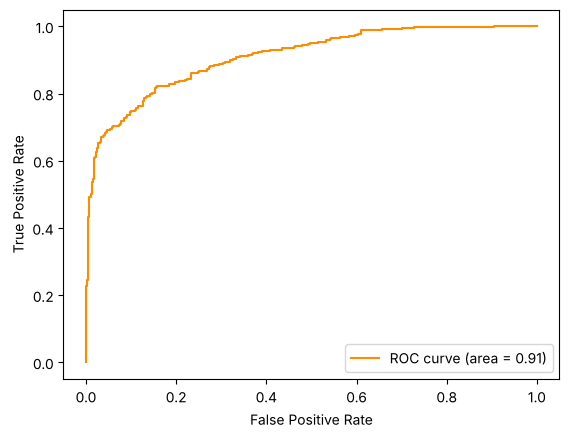

In [26]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_Test, model.predict(X_Test))
                        
roc_auc = auc(fpr, tpr)

plt.plot(fpr,tpr,color='darkorange',label='ROC curve (area = %0.2f)' % roc_auc)
plt.legend(loc="lower right")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.show()

## How good is that?

An AUC of about 0.91. "The best you can get is one." To judge it, compare it with the other
methods on the same training and test slices (computed with scikit-learn, not in this notebook):

- `fAlpha` alone: 0.78
- logistic regression, on standardized features: 0.83
- this small network: about 0.91 (your run will differ a little: training is random)
- scikit-learn's `HistGradientBoostingClassifier` with its default settings: 0.93

That is the benchmark paper's conclusion on one dataset. On tables of high-level features, boosted
decision trees are hard to beat; a deep network needs a lot of data and capacity before it wins, and
"the difference is not necessarily that big". If you are in the regime "where you have little data,
boosted decision trees will most likely be the best approach."

**For your project**, trying a deep network is now a matter of copying this notebook and changing the
dataset. The goal is "a non-trivial result" after going "through all the steps", not a great one. For many
models, one notebook per model (copied and changed) keeps things clear, and for long training, save the
model every epoch (a callback) and look at it from another notebook while it trains.